In [1]:
#import librabries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

In [2]:
#1. import database

conn = sqlite3.connect('customer_churn.db')


sql_query ="""

         SELECT name
         FROM sqlite_master
         WHERE type='table';

"""

tables = pd.read_sql(sql_query , conn)

#df= df_db_customer.copy()
#create df for each table

for table_name in tables['name']:
    df=pd.read_sql(f"SELECT * FROM {table_name}", conn)
    globals()[f"df_{table_name}"]=df
    print(f"Created dataframe: df_{table_name}")
conn.close()

Created dataframe: df_db_customer
Created dataframe: df_db_subscription
Created dataframe: df_db_support


In [3]:
#Print table names and columns
conn= sqlite3.connect('customer_churn.db')  #build connection b/w db

for table_name in tables['name']:
    print(f"\nTable Name: {table_name}")
    #Get col info
    columns_query=f"PRAGMA table_info({table_name});" #'prega' used to take table data  
    columns=pd.read_sql(columns_query, conn)
    print("Columns:")
    print(columns['name'].tolist())

conn.close()  #close connection


Table Name: db_customer
Columns:
['customerid', 'name', 'country', 'state', 'gender', 'dob', 'interests', 'pincode']

Table Name: db_subscription
Columns:
['customerid', 'subscription_start_date', 'subscription_type', 'renewal_date', 'plan_type', 'contract_type', 'cancellation_date', 'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score']

Table Name: db_support
Columns:
['customerid', 'complaint_date', 'escalations', 'csat_score', 'col_1', 'comment']


#2.  DATA CLEANING

In [4]:
df_db_customer.head()#shows top 5 data rows
df_db_customer.tail()# shows last 5 rows

,customerid,name,country,state,gender,dob,interests,pincode
16,0020-JDNXP,rikim,India,Meghalaya,Female,1994-08-19 00:00:00,NaN,None
17,0021-IKXGC,vishakha,India,Rajasthan,Female,2000-09-02 00:00:00,NaN,None
18,0022-TCJCI,raghvendra,India,Telangana,Male,1983-12-30 00:00:00,NaN,None
19,0023-HGHWL,rishabh,India,Uttar Pradesh,Men,1991-05-14 00:00:00,NaN,None
20,0023-UYUPN,sudevi,India,Maharashtra,Women,1977-10-06 00:00:00,NaN,None


In [5]:
df_db_customer.info()


<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   customerid  21 non-null     str   
 1   name        21 non-null     str   
 2   country     18 non-null     str   
 3   state       21 non-null     str   
 4   gender      21 non-null     str   
 5   dob         21 non-null     str   
 6   interests   4 non-null      str   
 7   pincode     0 non-null      object
dtypes: object(1), str(7)
memory usage: 2.5+ KB


In [6]:
# drop col-  intrest and pincode
# rename col - name
# change dtype - dob
# data standardization - gender
# fix missing values - country col

In [7]:
#rename 
df_db_customer.rename(columns = {'name':'customer_name'}, inplace=True)
df_db_customer

,customerid,customer_name,country,state,gender,dob,interests,pincode
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00,travel,None
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00,NaN,None
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00,movie,None
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00,NaN,None
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00,drama,None
5,0013-MHZWF,durga,NaN,Delhi,Women,1988-12-10 00:00:00,NaN,None
6,0013-SMEOE,mina,India,Meghalaya,Female,1976-09-21 00:00:00,NaN,None
7,0014-BMAQU,madan,India,Rajasthan,Male,1999-03-14 00:00:00,NaN,None
8,0015-UOCOJ,maya,NaN,Kathmandu,Women,1985-07-07 00:00:00,NaN,None
9,0016-QLJIS,arjun,Nepal,Kathmandu,Male,1993-10-29 00:00:00,NaN,None


In [8]:
#drop columns 
#df_db_customer.drop(df_db_customer.columns[-2:],axis = 1)
#df_db_customer.columns[6:]
df_db_customer.drop(columns=['interests', 'pincode'], inplace=True)

In [9]:
df_db_customer

,customerid,customer_name,country,state,gender,dob
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00
5,0013-MHZWF,durga,NaN,Delhi,Women,1988-12-10 00:00:00
6,0013-SMEOE,mina,India,Meghalaya,Female,1976-09-21 00:00:00
7,0014-BMAQU,madan,India,Rajasthan,Male,1999-03-14 00:00:00
8,0015-UOCOJ,maya,NaN,Kathmandu,Women,1985-07-07 00:00:00
9,0016-QLJIS,arjun,Nepal,Kathmandu,Male,1993-10-29 00:00:00


In [10]:
df_db_customer.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   customerid     21 non-null     str  
 1   customer_name  21 non-null     str  
 2   country        18 non-null     str  
 3   state          21 non-null     str  
 4   gender         21 non-null     str  
 5   dob            21 non-null     str  
dtypes: str(6)
memory usage: 2.2 KB


In [11]:
#change dtype - dob
df_db_customer['dob']=pd.to_datetime(df_db_customer['dob'])
#df_db_customer['dob']

In [12]:
str_cols=df_db_customer.select_dtypes(include=['string', 'str']).columns
df_db_customer[str_cols]= df_db_customer[str_cols].astype('object')

In [13]:
#data standardization - gender
df_db_customer['gender'].unique()
df_db_customer['gender']=df_db_customer['gender'].replace({'Men':'Male', 'Women':'Female'})

In [14]:
df_db_customer['gender'].unique()


array(['Male', 'Female'], dtype=object)

In [15]:
# fix missing values - country 

df_db_customer[df_db_customer['country'].isna()]


,customerid,customer_name,country,state,gender,dob
5,0013-MHZWF,durga,NaN,Delhi,Female,1988-12-10
8,0015-UOCOJ,maya,NaN,Kathmandu,Female,1985-07-07
12,0018-NYROU,chitra,NaN,Telangana,Female,2004-12-01


In [16]:
df_db_customer[['country','state']]

,country,state
0,India,Maharashtra
1,India,Karnataka
2,India,Delhi
3,India,Nagaland
4,India,Delhi
5,NaN,Delhi
6,India,Meghalaya
7,India,Rajasthan
8,NaN,Kathmandu
9,Nepal,Kathmandu


In [17]:
#country & state - ynique value pair

sate_country_mapping=df_db_customer.dropna(subset=['country']).set_index('state')['country'].to_dict()

df_db_customer['country']=df_db_customer['country'].fillna(df_db_customer['state'].map(sate_country_mapping))

In [18]:

df_db_customer[df_db_customer['country'].isna()]

,customerid,customer_name,country,state,gender,dob


In [19]:
df_db_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaN,NaN,13.99,627,12
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaN,NaN,6.99,210,34
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaN,NaN,22.99,1725,8
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88


In [20]:
df_db_subscription.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customerid               21 non-null     str    
 1   subscription_start_date  21 non-null     str    
 2   subscription_type        21 non-null     str    
 3   renewal_date             21 non-null     str    
 4   plan_type                21 non-null     str    
 5   contract_type            21 non-null     str    
 6   cancellation_date        6 non-null      str    
 7   cancellation_reason      6 non-null      str    
 8   monthly_charges          21 non-null     float64
 9   cltv                     21 non-null     int64  
 10  churn_score              21 non-null     int64  
dtypes: float64(1), int64(2), str(8)
memory usage: 3.1 KB


In [21]:
date_col=['subscription_start_date','renewal_date','cancellation_date']

df_db_subscription[date_col]=df_db_subscription[date_col].apply(pd.to_datetime)
df_db_subscription.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   customerid               21 non-null     str           
 1   subscription_start_date  21 non-null     datetime64[us]
 2   subscription_type        21 non-null     str           
 3   renewal_date             21 non-null     datetime64[us]
 4   plan_type                21 non-null     str           
 5   contract_type            21 non-null     str           
 6   cancellation_date        6 non-null      datetime64[us]
 7   cancellation_reason      6 non-null      str           
 8   monthly_charges          21 non-null     float64       
 9   cltv                     21 non-null     int64         
 10  churn_score              21 non-null     int64         
dtypes: datetime64[us](3), float64(1), int64(2), str(5)
memory usage: 2.7 KB


In [22]:
df_db_support.head()

,customerid,complaint_date,escalations,csat_score,col_1,comment
0,0003-MKNFE,2024-08-28 00:00:00,N,60,None,service issue
1,0003-MKNFE,2024-08-28 00:00:00,Y,10,None,demaned refund
2,0013-EXCHZ,2024-01-20 00:00:00,Y,20,None,NaN
3,0013-MHZWF,2025-03-18 00:00:00,N,90,None,guidance to renew
4,0013-SMEOE,2024-11-01 00:00:00,N,30,None,NaN


In [23]:
df_db_support.info()

<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   customerid      9 non-null      str   
 1   complaint_date  9 non-null      str   
 2   escalations     9 non-null      str   
 3   csat_score      9 non-null      int64 
 4   col_1           0 non-null      object
 5   comment         4 non-null      str   
dtypes: int64(1), object(1), str(4)
memory usage: 895.0+ bytes


In [24]:
str_cols2=df_db_support.select_dtypes(include=['string', 'str']).columns
df_db_support[str_cols2]= df_db_support[str_cols2].astype('object')

In [25]:
df_db_support.drop(columns=['col_1','comment'], inplace=True)

In [26]:
df_db_support['complaint_date']=pd.to_datetime(df_db_support['complaint_date'])

In [27]:
df_db_support.info()

<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   customerid      9 non-null      object        
 1   complaint_date  9 non-null      datetime64[us]
 2   escalations     9 non-null      object        
 3   csat_score      9 non-null      int64         
dtypes: datetime64[us](1), int64(1), object(2)
memory usage: 420.0+ bytes


#3. Feature engg & Data Analysis


In [28]:
#create a new col - churn flag 
df_db_subscription['churn_flag']= np.where(df_db_subscription['cancellation_date'].notna(),1,0)

In [29]:
df_db_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score,churn_flag
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,12,0
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,NaN,6.99,210,34,0
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,NaN,22.99,1725,8,0
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88,1


In [30]:
#first fix support table duplicates then merge 
df= (df_db_subscription
    .merge(df_db_customer, on ='customerid', how='left')
    .merge(df_db_support, on ='customerid', how='left'))

In [31]:
df.shape

(23, 20)

In [32]:
df_db_subscription['customerid'].nunique()

21

In [33]:
df_db_customer['customerid'].nunique()

21

In [34]:
df_db_support['customerid'].nunique()

7

In [35]:
df_db_support['customerid'].size

9

In [36]:
df_db_support

,customerid,complaint_date,escalations,csat_score
0,0003-MKNFE,2024-08-28,N,60
1,0003-MKNFE,2024-08-28,Y,10
2,0013-EXCHZ,2024-01-20,Y,20
3,0013-MHZWF,2025-03-18,N,90
4,0013-SMEOE,2024-11-01,N,30
5,0017-IUDMW,2024-04-10,Y,25
6,0019-EFAEP,2024-09-27,Y,30
7,0022-TCJCI,2024-09-13,Y,10
8,0022-TCJCI,2024-09-14,N,90


In [37]:
df_db_support['complaint_count']=df_db_support.groupby('customerid')['customerid'].transform('count')

In [38]:
df_db_support=df_db_support.sort_values('complaint_date').drop_duplicates('customerid', keep ='last')

In [39]:
#first df
df= (df_db_subscription
    .merge(df_db_customer, on ='customerid', how='left')
    .merge(df_db_support, on ='customerid', how='left'))

In [40]:
df.shape

(21, 21)

In [41]:
df.to_csv('exported_churn_data.csv', index=False )

In [42]:
#Data Analysis

In [43]:
#1. churn rate


In [44]:
df.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count'],
      dtype='str')

In [45]:
churn_rate= df['churn_flag'].mean()*100
print('Churn Rate:', round(churn_rate,2),"%" )

Churn Rate: 28.57 %


In [46]:
#2. Retention rate
retention_rate=100-churn_rate
print('Rentention Rate:', round(retention_rate,2),"%" )

Rentention Rate: 71.43 %


In [47]:
#3. churn by Plan type
churn_by_plan= (df.groupby('plan_type')['churn_flag'].mean().mul(100).round(2).reset_index(name='churn_rate_pct'))

print( churn_by_plan)

  plan_type  churn_rate_pct
0     Basic           60.00
1   Premium           14.29
2  Standard           22.22


In [48]:
# APRU- average revenue per user

arpu= df['monthly_charges'].mean()
print('APRU=', round(arpu,2))

APRU= 18.85


In [49]:
# Avg customer tenure
# count of days users has used our service : cancellation date else current date

today = pd.Timestamp.today()

df['tenure_days']= np.where(
        df['cancellation_date'].notna(),

   ( df['cancellation_date']-df['subscription_start_date']).dt.days,
    (today-df['subscription_start_date'] ).dt.days
)

avg_tenure=df['tenure_days'].mean()
print("Avg Tenure(Days)=" , round(avg_tenure),0)

Avg Tenure(Days)= 1581 0


In [50]:
# Revenue at risk - revenue lost from churned users

revenue_at_risk=df.loc[df['churn_flag']==1, 'monthly_charges' ].sum()
print('Revenue at Risk(Rs k):',revenue_at_risk)

Revenue at Risk(Rs k): 73.94


In [51]:
# Esclation Rate: problem is not solved in ine time

escalation_rate=(df['escalations']== 'Y').mean()*100
print("Escalation Rate=", round(escalation_rate,2),"%")


Escalation Rate= 19.05 %


In [52]:
# Avg complaint per user
avg_complaints=df['complaint_count'].sum() / df['customerid'].nunique()
print("Avg Complaints per user =", round(avg_complaints,2))

Avg Complaints per user = 0.43


In [53]:
#coorelation escalation vs churn

df['escalations']= np.where(df['escalations']=='Y',1,0)#encoding strng to int type

corr_df = df[['escalations', 'churn_flag']].dropna()

coorelation =corr_df['escalations'].corr(df['churn_flag'])

print("Coorelation b/w escalation and churn is:", round(coorelation,2))

Coorelation b/w escalation and churn is: 0.77


In [54]:
# churn risk- create a column using existing col
conditions=[

    (df['churn_score']<50),
    (df['churn_score']>=50) & (df['churn_score']<70),
    (df['churn_score']>=70)
]
choices= ['low','med', 'high']
df['churn_risk']= np.select(conditions, choices , default='unknown')

In [55]:
df[['churn_risk','churn_score']].head()

,churn_risk,churn_score
0,low,12
1,high,91
2,low,34
3,low,8
4,high,88


In [56]:
print("Escalations unique values:")
print(corr_df['escalations'].value_counts())

print("\nChurn Flag unique values:")
print(corr_df['churn_flag'].value_counts())

Escalations unique values:
escalations
0    17
1     4
Name: count, dtype: int64

Churn Flag unique values:
churn_flag
0    15
1     6
Name: count, dtype: int64


In [57]:
df.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count',
       'tenure_days', 'churn_risk'],
      dtype='str')

In [58]:
# 1. Let's see what dataframes we actually have in memory
available_tables = [var for var in globals() if var.startswith('df_')]
print("Available dataframes:", available_tables)

# 2. Let's check which dataframe contains 'escalations'
for table in available_tables:
    if 'escalations' in globals()[table].columns:
        print(f"✨ Found 'escalations' inside: {table}")
    if 'churn_flag' in globals()[table].columns:
        print(f"✨ Found 'churn_flag' inside: {table}")

Available dataframes: ['df_db_customer', 'df_db_subscription', 'df_db_support']
✨ Found 'churn_flag' inside: df_db_subscription
✨ Found 'escalations' inside: df_db_support


In [61]:
import pandas as pd

# 1. Merge the subscription data and support data together using customer_id
merged_df = pd.merge(df_db_subscription, df_db_support, on='customerid', how='inner')

# 2. Correctly convert 'escalations' to a number
merged_df['escalations'] = pd.to_numeric(merged_df['escalations'], errors='coerce').fillna(0)

# 3. Properly map the categorical 'churn_flag' strings to binary numbers
merged_df['churn_flag'] = merged_df['churn_flag'].astype(str).str.strip().str.upper().map({'Y': 1, 'N': 0, 'YES': 1, 'NO': 0}).fillna(0)

# 4. Filter missing data and compute the final correlation coefficient
corr_df = merged_df[['escalations', 'churn_flag']].dropna()
correlation = corr_df['escalations'].corr(corr_df['churn_flag'])

print("Correlation b/w escalation and churn is:", round(correlation, 4))

Correlation b/w escalation and churn is: nan


C:\Users\harsh\anaconda3\Lib\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]


In [62]:
# 1. Rebuild the master df with customer, subscription, and deduplicated support data
df = (
    df_db_subscription
    .merge(df_db_customer, on='customerid', how='left')
    .merge(df_db_support, on='customerid', how='left')
)

# 2. Convert escalations: 'Y' -> 1, 'N' -> 0, and customers without complaints (NaN) -> 0
df['escalations_flag'] = df['escalations'].fillna('N').map({'Y': 1, 'N': 0}).astype(int)

# 3. Escalation Rate (%)
escalation_rate = df['escalations_flag'].mean() * 100
print(f"Escalation Rate: {round(escalation_rate, 2)}%")

# 4. Churn Rate for Escalated vs Non-Escalated customers
escalation_churn = df.groupby('escalations_flag')['churn_flag'].agg(
    total_customers='count',
    churned_customers='sum',
    churn_rate=lambda x: round(x.mean() * 100, 2)
).reset_index()

print("\nChurn by Escalation Status (0 = No Escalation, 1 = Escalated):")
print(escalation_churn)

# 5. Correlation between Escalation and Churn
correlation = df['escalations_flag'].corr(df['churn_flag'].astype(int))
print(f"\nCorrelation b/w escalation and churn: {round(correlation, 4)}")

Escalation Rate: 19.05%

Churn by Escalation Status (0 = No Escalation, 1 = Escalated):
   escalations_flag  total_customers  churned_customers  churn_rate
0                 0               17                  2       11.76
1                 1                4                  4      100.00

Correlation b/w escalation and churn: 0.767


In [63]:
# 1. Rebuild the master merged dataframe cleanly
df = (
    df_db_subscription
    .merge(df_db_customer, on='customerid', how='left')
    .merge(df_db_support, on='customerid', how='left')
)

# 2. Add tenure and churn_risk features
today = pd.Timestamp.today()
df['tenure_days'] = np.where(
    df['cancellation_date'].notna(),
    (df['cancellation_date'] - df['subscription_start_date']).dt.days,
    (today - df['subscription_start_date']).dt.days
)

conditions = [
    (df['churn_score'] < 50),
    (df['churn_score'] >= 50) & (df['churn_score'] < 70),
    (df['churn_score'] >= 70)
]
df['churn_risk'] = np.select(conditions, ['low', 'med', 'high'], default='unknown')

# 3. Clean escalations and churn_flag without overwriting them to 0
# Support table has 'Y', 'N', and missing values for users who never raised a complaint
df['escalations_num'] = df['escalations'].map({'Y': 1, 'N': 0}).fillna(0).astype(int)
df['churn_flag_num'] = df['churn_flag'].astype(int)

# 4. Escalation metrics & verification
print("--- Escalations & Churn Distribution ---")
print("Escalation values:\n", df['escalations_num'].value_counts())
print("\nChurn values:\n", df['churn_flag_num'].value_counts())

escalation_rate = df['escalations_num'].mean() * 100
print(f"\nEscalation Rate: {round(escalation_rate, 2)}%")

# 5. Correlation calculation
correlation = df['escalations_num'].corr(df['churn_flag_num'])
print(f"Correlation b/w escalation and churn is: {round(correlation, 4)}")

--- Escalations & Churn Distribution ---
Escalation values:
 escalations_num
0    17
1     4
Name: count, dtype: int64

Churn values:
 churn_flag_num
0    15
1     6
Name: count, dtype: int64

Escalation Rate: 19.05%
Correlation b/w escalation and churn is: 0.767


Visulalisation using matplotlin.pyplt

In [64]:
df_visual= df.copy()

In [65]:
df_visual.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,...,gender,dob,complaint_date,escalations,csat_score,complaint_count,tenure_days,churn_risk,escalations_num,churn_flag_num
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,...,Male,1982-04-12,NaT,NaN,NaN,NaN,2068.0,low,0,0
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,...,Male,1995-11-23,2024-08-28,Y,10.0,2.0,1501.0,high,1,1
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,NaN,6.99,210,...,Female,1978-02-15,NaT,NaN,NaN,NaN,1453.0,low,0,0
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,NaN,22.99,1725,...,Male,2001-08-30,NaT,NaN,NaN,NaN,2743.0,low,0,0
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,...,Female,1990-05-05,2024-01-20,Y,20.0,1.0,419.0,high,1,1


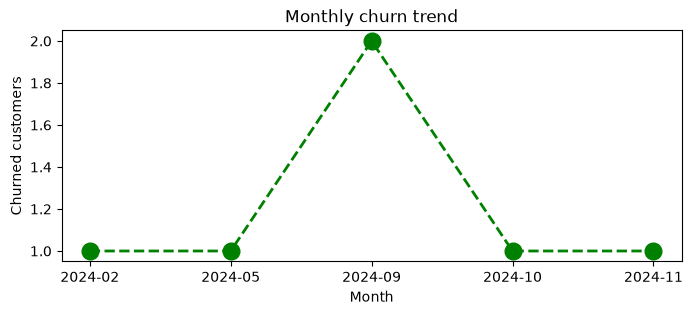

In [73]:
#Monthly churn trend(time series)
df_visual['cancellation_month']=df_visual['cancellation_date'].dt.to_period('M')

churn_trend= df_visual[df_visual['churn_flag']==1].groupby('cancellation_month').size()

plt.figure(figsize=(8,3))
plt.plot(churn_trend.index.astype(str), churn_trend.values, color='green', marker='o', linestyle='dashed', linewidth=2,markersize=12)

plt.title('Monthly churn trend')
plt.xlabel('Month')
plt.ylabel('Churned customers')
plt.show()

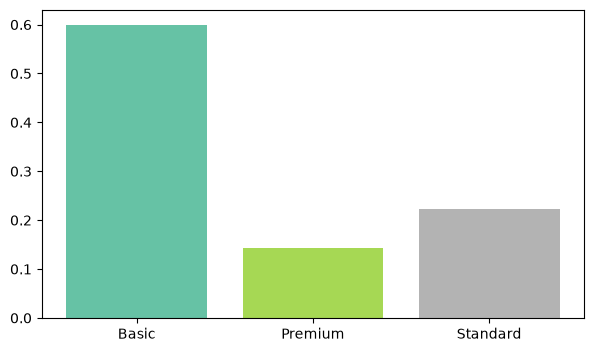

In [80]:
#churnby plan type

churn_plan=df_visual.groupby('plan_type')['churn_flag'].mean() 
colors=plt.cm.Set2(np.linspace(0,1,len(churn_plan)))
#colors=['yellow','purple','blue']
plt.figure(figsize=(7,4))
plt.bar(churn_plan.index,churn_plan.values, color=colors)
plt.show()

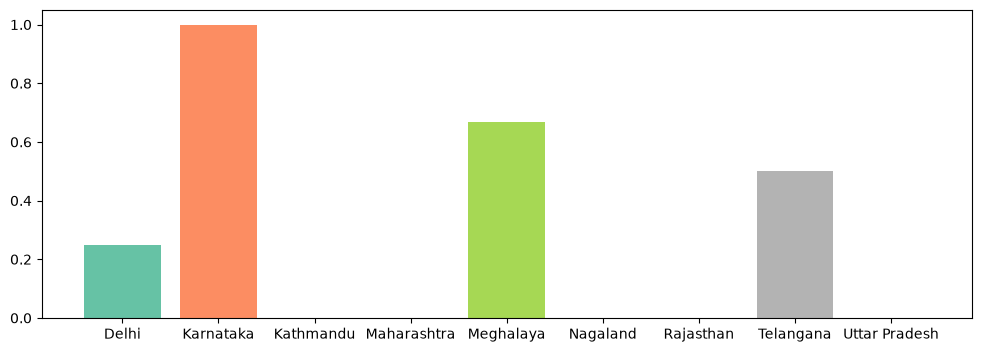

In [82]:
#Churn by states
#churnby plan type

churn_plan=df_visual.groupby('state')['churn_flag'].mean() 
colors=plt.cm.Set2(np.linspace(0,1,len(churn_plan)))
#colors=['yellow','purple','blue']
plt.figure(figsize=(12,4))
plt.bar(churn_plan.index,churn_plan.values, color=colors)
plt.show()

In [84]:
#visualization using seaborn


In [85]:
#encoding - str to mnumeric

df_visual[['plan_type','contract_type','churn_score','churn_flag','churn_risk','escalations']].head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,Standard,Annual,12,0,low,NaN
1,Premium,Annual,91,1,high,Y
2,Basic,Monthly,34,0,low,NaN
3,Premium,Annual,8,0,low,NaN
4,Standard,Monthly,88,1,high,Y


In [92]:
df_encoded.head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,2,0,12,0,1,0
1,1,0,91,1,0,1
2,0,1,34,0,1,0
3,1,0,8,0,1,0
4,2,1,88,1,0,1


In [93]:
# inncorrect mr=ethod of encoding as numbers are not assigned based on priority
df_encoded=df_visual[['plan_type','contract_type','churn_score','churn_flag','churn_risk','escalations']]
df_encoded['escalations'] = df_encoded['escalations'].map({'Y': 1, 'N': 0}).fillna(0).astype(int)
categorical_cols=['plan_type','contract_type','churn_risk']

for col in categorical_cols:
    df_encoded[col]= df_encoded[col].astype('category').cat.codes

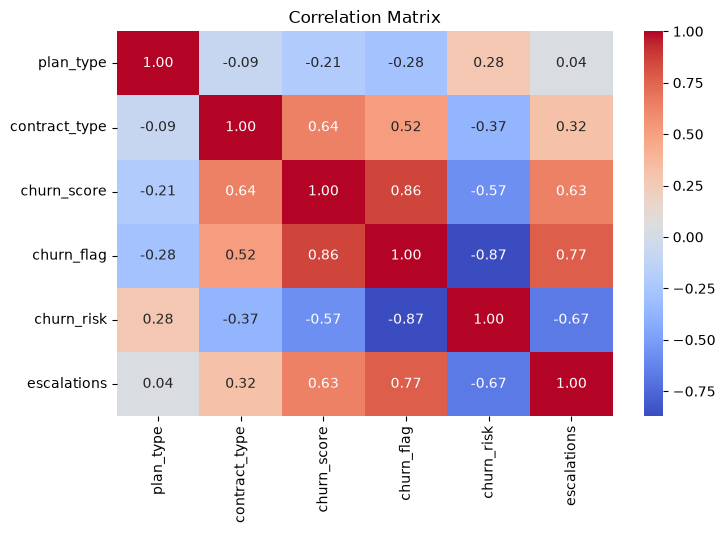

In [96]:
#Heatmap (corr matrix)
# Heatmap (corr matrix)
plt.figure(figsize=(8, 5))
sns.heatmap(df_encoded.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix')

plt.show()

In [103]:
# correct method of encoding- based on priority
df_encoded=df_visual[['plan_type','contract_type','churn_score','churn_flag','churn_risk','escalations']]
df_encoded['escalations'] = df_encoded['escalations'].map({'Y': 1, 'N': 0}).fillna(0).astype(int)
order_mappings ={
    'plan_type' : ['Basic','Standard' ,'Premium'],
    'contract_type' :['Monthly','Annual'] ,
    'churn_risk':['low','med','high']
     }

for col , order in order_mappings.items():
    df_encoded[col]= pd.Categorical(df_encoded[col].astype('category'), categories=order , ordered=True).codes

In [104]:
df_visual[['plan_type','contract_type','churn_score','churn_flag','churn_risk','escalations']]

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,Standard,Annual,12,0,low,NaN
1,Premium,Annual,91,1,high,Y
2,Basic,Monthly,34,0,low,NaN
3,Premium,Annual,8,0,low,NaN
4,Standard,Monthly,88,1,high,Y
5,Standard,Annual,22,0,low,N
6,Basic,Monthly,79,1,high,N
7,Premium,Annual,5,0,low,NaN
8,Standard,Monthly,34,0,low,NaN
9,Basic,Annual,41,0,low,NaN


<Axes: >

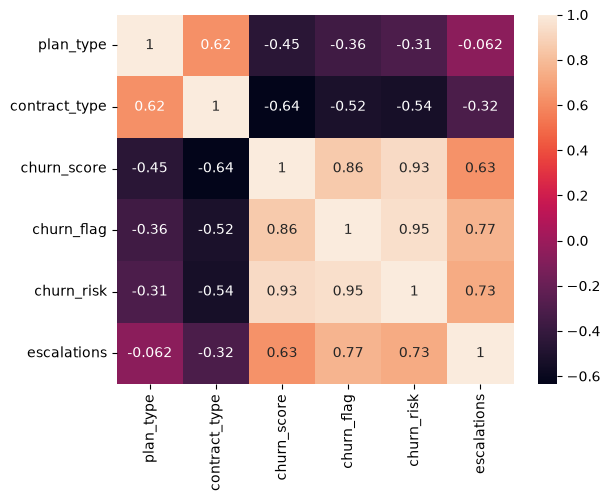

In [107]:
#Heatmap 

sns.heatmap(df_encoded.corr(),annot=True) 

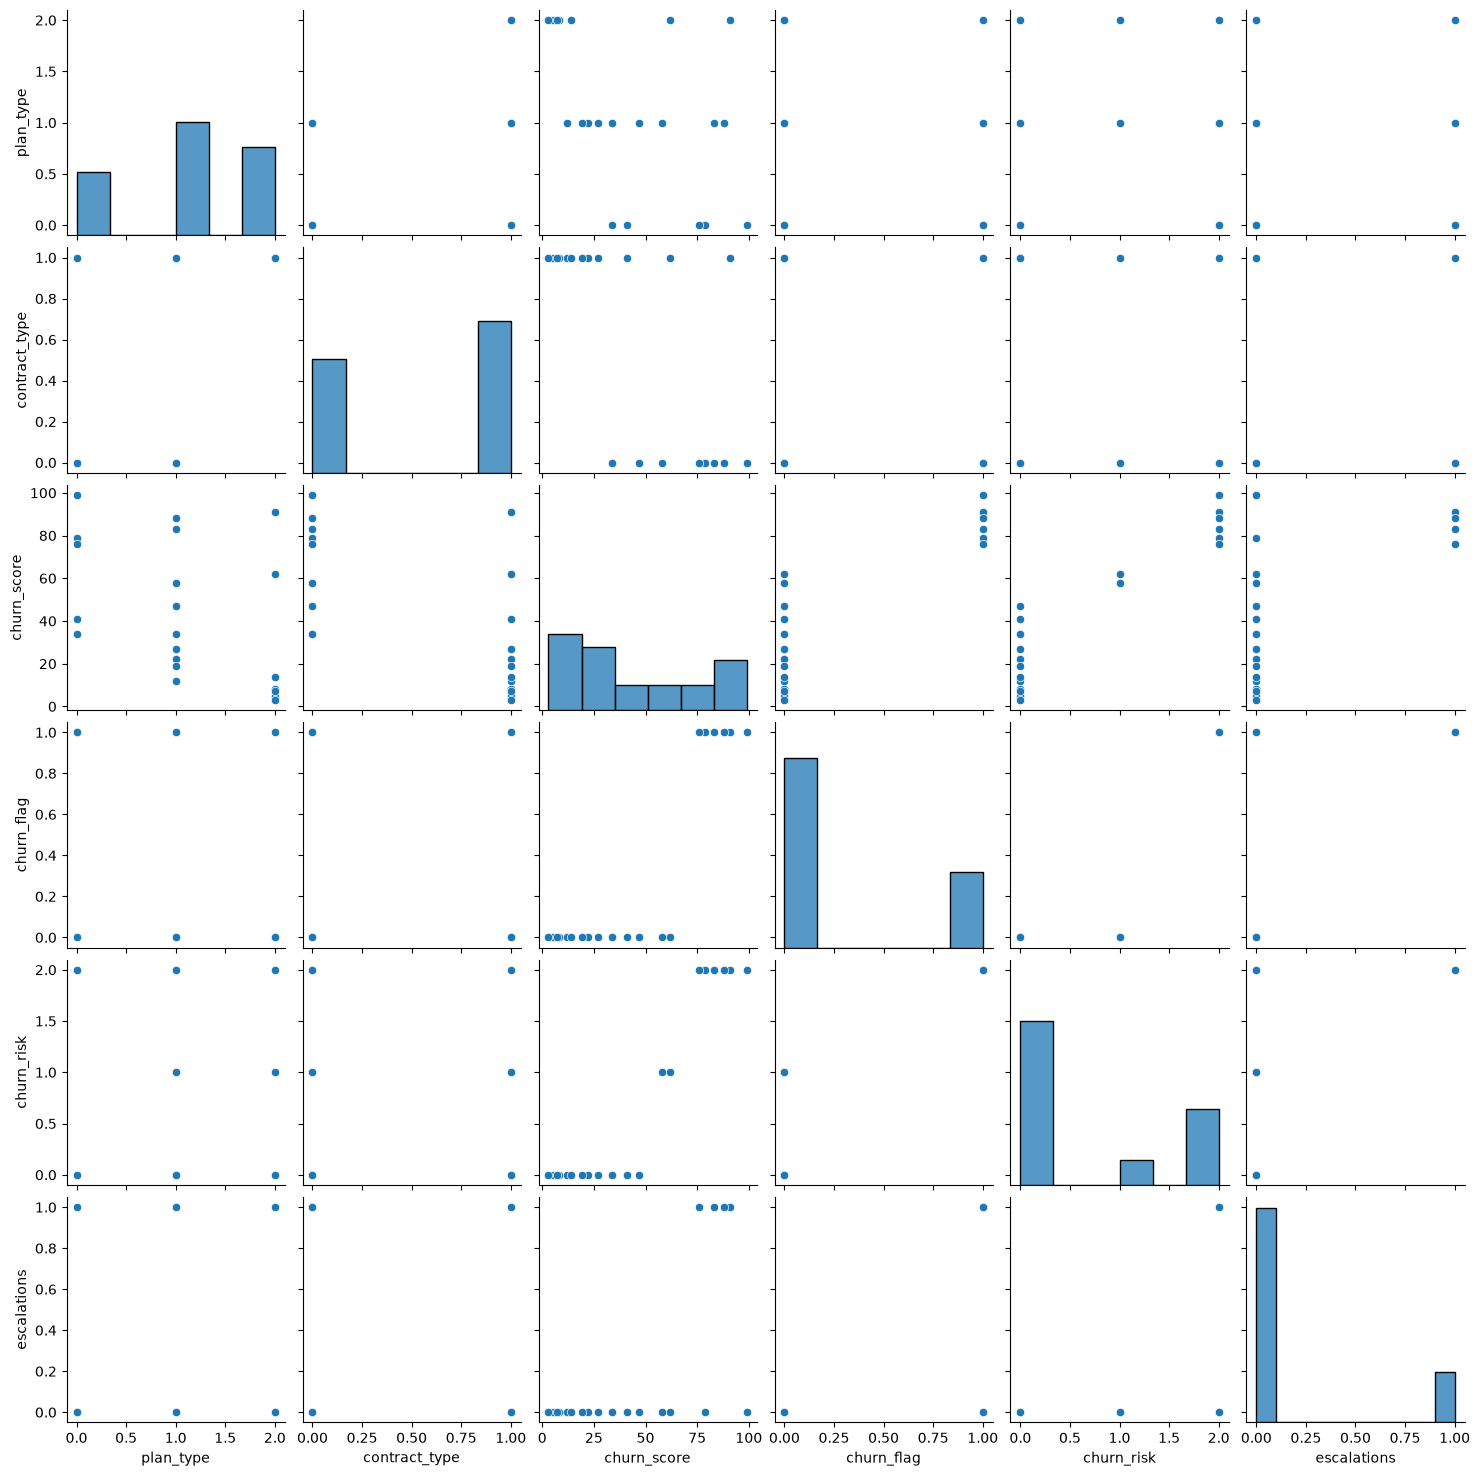

In [109]:
#Pairplot -- relationship b/w dataset
sns.pairplot(df_encoded)

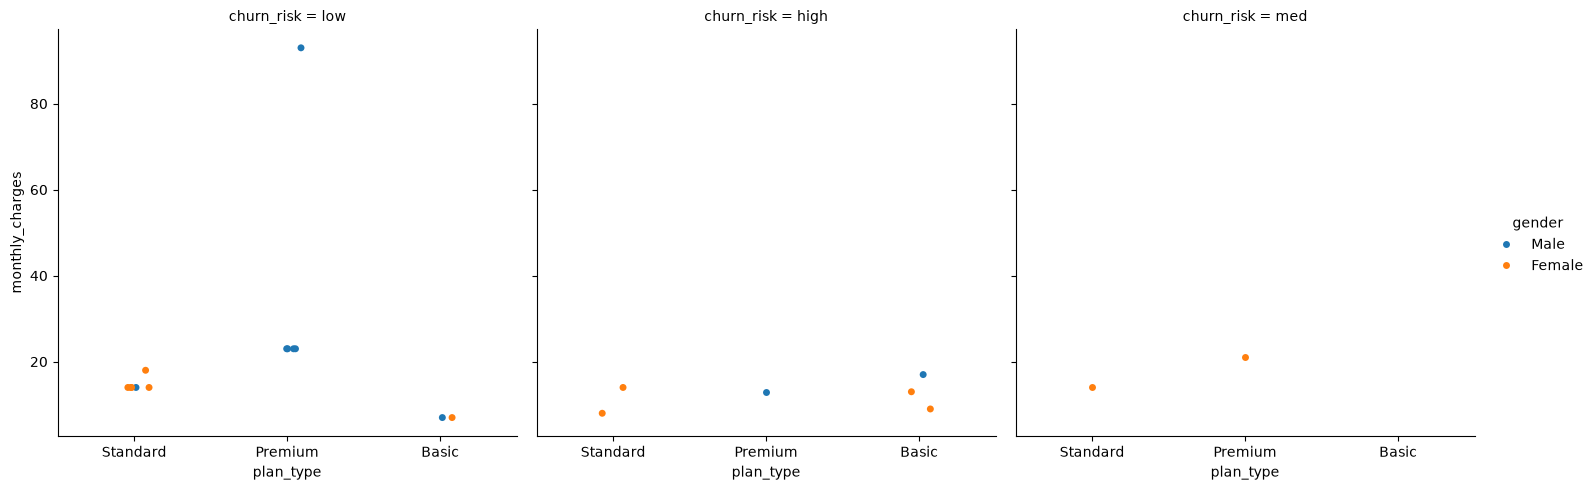

In [113]:
# catplt/ Facegrid plot-- multi dimension comp
sns.catplot(data= df_visual,
    x='plan_type',
    y= 'monthly_charges',
    hue='gender',
    col='churn_risk'
)

In [115]:
#Pivot table
pd.pivot_table(
    df_visual,
    values='churn_flag',
    index='plan_type',
    aggfunc='mean'
).reset_index()

,plan_type,churn_flag
0,Basic,0.600000
1,Premium,0.142857
2,Standard,0.222222


In [117]:
pd.pivot_table(
    df_visual,
    index='plan_type',
    values=['monthly_charges','customerid','churn_flag'],
    
    aggfunc= {
        'monthly_charges':'sum',
        'customerid':'nunique',
        'churn_flag':'mean'
    }
)

,churn_flag,customerid,monthly_charges
plan_type,,,
Basic,0.600000,5,52.95
Premium,0.142857,7,218.93
Standard,0.222222,9,123.91
